In [1]:
pip install pandas==2.2.3

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install matplotlib==3.10.0

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install seaborn==0.13.2

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

from IPython.display import display, HTML
display(HTML("<style>.container { width:150% !important; }</style>"))
pd.options.display.max_columns=400
pd.options.display.max_rows=8000

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df_outages = pd.read_csv("data/outage_report_summaries.csv")
df_services = pd.read_csv("data/cloud_service_risk_ratings.csv")
# Filter first dummy record of file
df_services = df_services[df_services['service_provider'].str.contains('BAD CLOUD EXAMPLE') == False]

In [6]:
#df_outages

In [7]:
#df_services

In [8]:
df_outages1 = df_outages[df_outages['cloud_provider'].str.contains('AWS|GCP|Azure|MongoDB|IBM|Oracle') == False] # Exclude to view  not in != Oracle 
df_outages1

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output


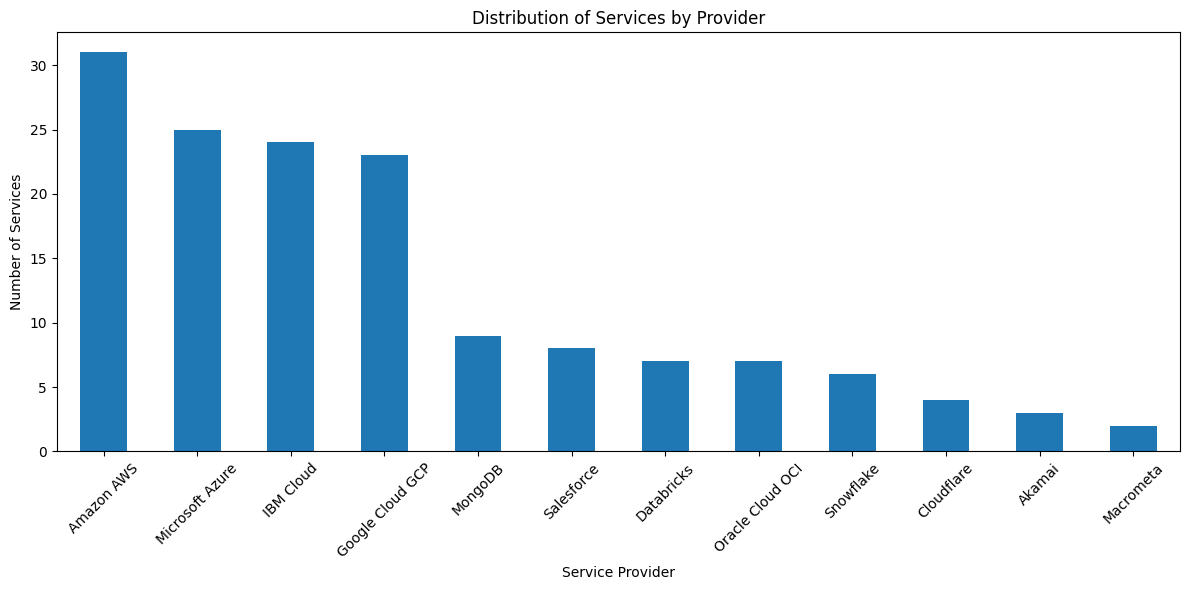

In [9]:
# 1.Service Provider Distribution:
df = df_services
plt.figure(figsize=(12, 6))
df['service_provider'].value_counts().plot(kind='bar')
plt.title('Distribution of Services by Provider')
plt.xlabel('Service Provider')
plt.ylabel('Number of Services')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

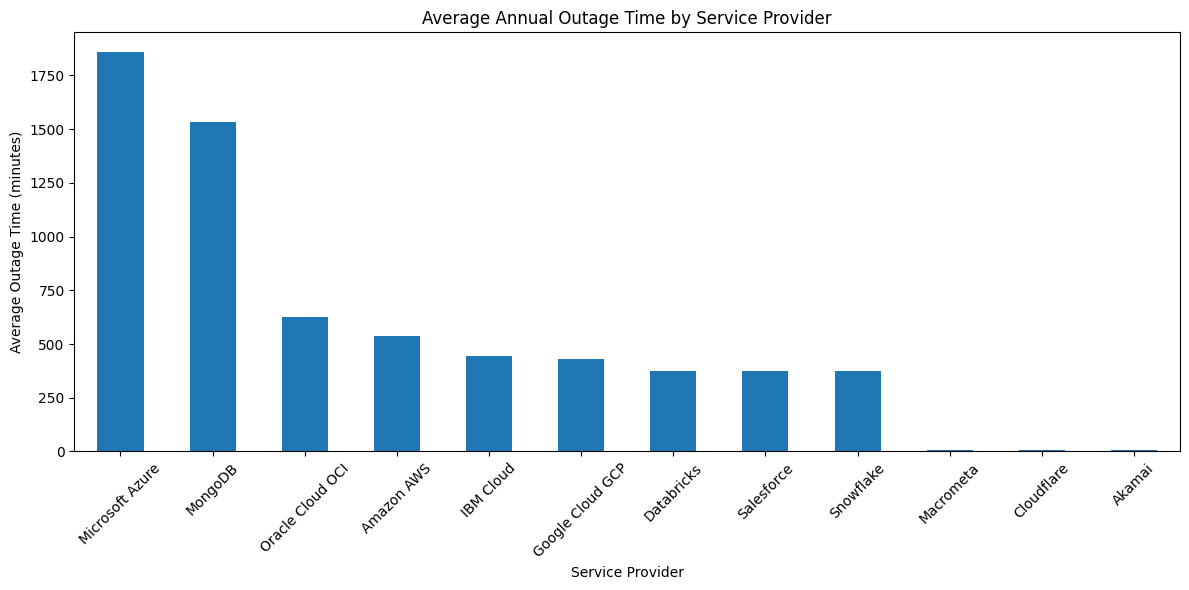

In [10]:
# 2.Average Annual Outage Time by Service Provider:
plt.figure(figsize=(12, 6))
df.groupby('service_provider')['webscraper_annual_period_service_down_per_year_in_minutes'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Average Annual Outage Time by Service Provider')
plt.xlabel('Service Provider')
plt.ylabel('Average Outage Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

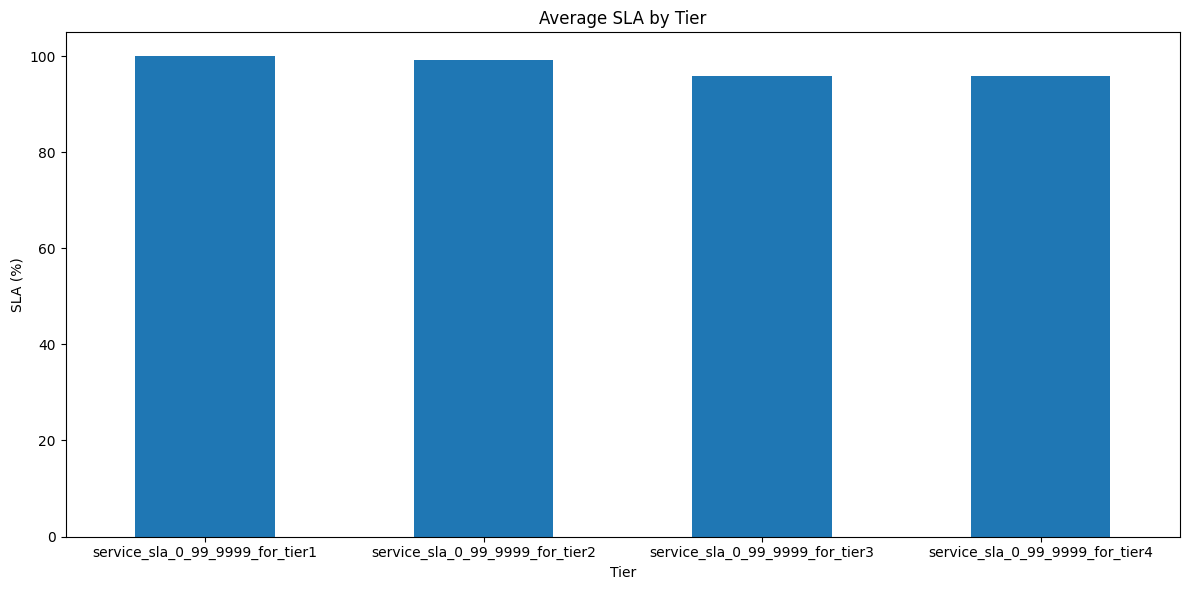

In [11]:
# 3.Service SLA Tiers Comparison:
plt.figure(figsize=(12, 6))
df[['service_sla_0_99_9999_for_tier1', 'service_sla_0_99_9999_for_tier2', 'service_sla_0_99_9999_for_tier3', 'service_sla_0_99_9999_for_tier4']].mean().plot(kind='bar')
plt.title('Average SLA by Tier')
plt.xlabel('Tier')
plt.ylabel('SLA (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

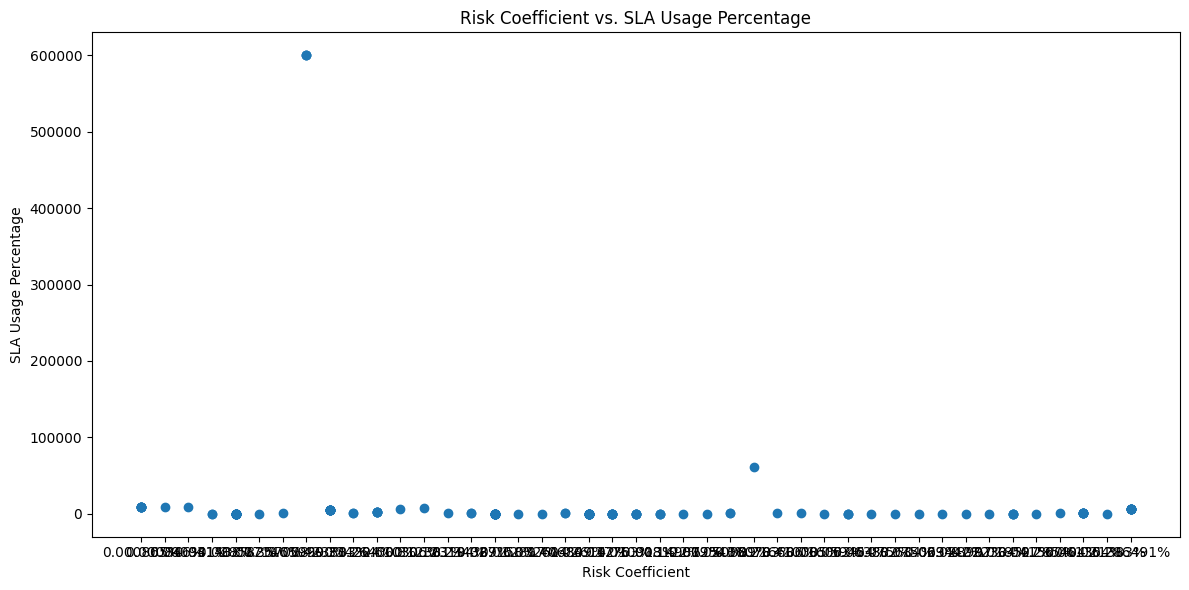

In [12]:
# 4.Risk Coefficient vs. SLA Usage Percentage:
plt.figure(figsize=(12, 6))
plt.scatter(df['riskcoef_per_service_from_gap_expected_actual_time_down'], df['service_sla_usage_percentage'])
plt.title('Risk Coefficient vs. SLA Usage Percentage')
plt.xlabel('Risk Coefficient')
plt.ylabel('SLA Usage Percentage')
plt.tight_layout()
plt.show()

In [13]:
# Global
df_outages_dedup = df_outages.drop_duplicates(subset=['outage_timestamp','source_outage_report','cloud_provider','cloud_service','regions']).sort_values(by=['outage_timestamp'],ascending=True)
df_outages_dedup.to_csv('data/new_sorted_outages_dedup.csv', index=False)

In [14]:
df_outages_dedup.describe()

,outage_timestamp,duration_minutes,resolution,mitigation_steps
count,5.994000e+03,5994.000000,0.0,0.0
mean,1.691564e+09,6726.294962,NaN,NaN
std,5.255790e+07,55157.434609,NaN,NaN
min,1.576085e+09,0.000000,NaN,NaN
25%,1.626102e+09,103.000000,NaN,NaN
50%,1.722997e+09,345.000000,NaN,NaN
75%,1.731225e+09,460.000000,NaN,NaN
max,1.739359e+09,563040.000000,NaN,NaN


In [15]:
df_outages_dedup.shape[0]

5994

In [16]:
df_outages_dedup.head(10)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
1086,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1085,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1084,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1083,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1036,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,southafricanorth,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1020,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,brazilsoutheast,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1021,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,westus3,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1022,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,norwaywest,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1027,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,germanywestcentral,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1028,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,koreasouth,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...


In [17]:
df_outages_dedup.tail(10)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
2605,1.736440e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud VertexAI,us,tokyo singapore sydney mumbai,2025-01-09T16:20:00+00:00,2025-01-10T00:30:00+00:00,resolved,NaN,10 hours and 26 minutes,626,DNS errors and delay in ingestion of data,NaN,2025-01-09 22:20 - 2025-01-10 00:46 UTC,NaN,"Google Cloud VertexAI, Google Cloud DataStudio",NaN,Source Outage Report: outages_files/Google Clo...
2576,1.736440e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud DataStudio,asia-southeast1,tokyo singapore sydney mumbai,2025-01-09T16:20:00+00:00,2025-01-10T00:30:00+00:00,resolved,NaN,10 hours and 26 minutes,626,DNS errors and delay in ingestion of data,NaN,2025-01-09 22:20 - 2025-01-10 00:46 UTC,NaN,"Google Cloud VertexAI, Google Cloud DataStudio",NaN,Source Outage Report: outages_files/Google Clo...
2579,1.736440e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud DataStudio,europe-west9,tokyo singapore sydney mumbai,2025-01-09T16:20:00+00:00,2025-01-10T00:30:00+00:00,resolved,NaN,10 hours and 26 minutes,626,DNS errors and delay in ingestion of data,NaN,2025-01-09 22:20 - 2025-01-10 00:46 UTC,NaN,"Google Cloud VertexAI, Google Cloud DataStudio",NaN,Source Outage Report: outages_files/Google Clo...
2608,1.738256e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud VertexAI,asia-southeast1,mumbai (asia-south1) and singapore (asia-south...,2025-01-30T16:53:00+00:00,2025-02-02T07:00:00+00:00,investigating,NaN,"2 days, 17 hours, and 33 minutes",3933,Unknown,NaN,2025-01-31 03:00 UTC to 2025-02-02 07:00 UTC (...,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
2606,1.738256e+09,outages_files/Google Cloud Service Health - 20...,GCP,WORKSPACE_ACTIVITY data ingestion,asia-southeast1,mumbai (asia-south1) and singapore (asia-south...,2025-01-30T16:53:00+00:00,2025-02-02T07:00:00+00:00,investigating,NaN,"2 days, 17 hours, and 33 minutes",3933,Unknown,NaN,2025-01-31 03:00 UTC to 2025-02-02 07:00 UTC (...,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
2607,1.738256e+09,outages_files/Google Cloud Service Health - 20...,GCP,WORKSPACE_ACTIVITY data ingestion,asia-southeast1 and asia-south1,mumbai (asia-south1) and singapore (asia-south...,2025-01-30T16:53:00+00:00,2025-02-02T07:00:00+00:00,investigating,NaN,"2 days, 17 hours, and 33 minutes",3933,Unknown,NaN,2025-01-31 03:00 UTC to 2025-02-02 07:00 UTC (...,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
2609,1.738256e+09,outages_files/Google Cloud Service Health - 20...,GCP,Google Cloud VertexAI,asia-southeast1 and asia-south1,mumbai (asia-south1) and singapore (asia-south...,2025-01-30T16:53:00+00:00,2025-02-02T07:00:00+00:00,investigating,NaN,"2 days, 17 hours, and 33 minutes",3933,Unknown,NaN,2025-01-31 03:00 UTC to 2025-02-02 07:00 UTC (...,NaN,Google Cloud VertexAI,NaN,Source Outage Report: outages_files/Google Clo...
2885,1.739359e+09,outages_files/Google Cloud Service Health - In...,GCP,df,global-default,NaN,2025-02-12T11:20:00+00:00,2025-02-12T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
2886,1.739359e+09,outages_files/Google Cloud Service Health - In...,GCP,Google Cloud VertexAI,global-default,NaN,2025-02-12T11:20:00+00:00,2025-02-12T14:40:00+00:00,resolved,NaN,3 hours and 20 minutes. The root cause of the ...,200,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: outages_files/Google Clo...
2884,1.739359e+09,outages_files/Google Cloud Service Health - In...,GCP,Google Cloud Interconnect experienced elevated...,global-default,NaN,2025-02-12T11:20:00+00:0

In [18]:
print("done!")

done!


In [19]:
exit()